# Module 3 — Task 4: Cost-based threshold

**Business problem (brief, verbatim):**
> NovaFin processes thousands of transactions every day. Management wants to identify suspicious transactions while minimizing unnecessary investigation.

**Task 4 (brief, verbatim):**
> **Task 4 — Cost-based threshold.** Assume: Missed fraud cost ₹10,000 · False-positive investigation cost ₹500. Then find a threshold that minimizes expected operational cost.

**In plain words:** for every transaction, the Task 2 model gives a chance of fraud. The bank picks **one cut-off**: investigate everything above it, let everything below it through. A low cut-off wastes time on honest customers; a high one lets frauds slip through. Task 4 finds the cut-off with the lowest total cost.

```text
Total cost = ₹10,000 × frauds let through (missed)  +  ₹500 × honest transactions investigated for nothing
```

**Where this task sits:** data (Task 1) → supervised model (Task 2) → anomaly detection (Task 3) → **cost-based threshold (this task)**.

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | Load the scores from Tasks 2 and 3 |
| 2 | The threshold from the brief's costs: the line at 4.76% |
| 3 | Can the model's chances be trusted around the line? (calibration check) |
| 4 | Cross-check: try every cut-off on the training transactions (the "sweep") |
| 5 | The real cost on the 6,000 test transactions, used once |
| 6 | The finance view: counting each missed fraud at its real amount |
| 7 | Board view in ₹, per 1,000 transactions |
| 8 | Risks and limitations, including how the line moves if the costs change |
| 9 | What the results say |
| 10 | Save the outputs |

**Decisions used** (in `docs/decisions.md`): M3-18 what a missed fraud costs · M3-19 the line, the sweep and the calibration check · M3-20 scope and outputs.

## 0. Setup

Works locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.
- Runs in under a minute. Reads `outputs/task2/FINAL_M3_T2_fraud_scores.csv` and `outputs/task3/FINAL_M3_T3_anomaly_scores.csv`, so Tasks 2 and 3 must have run once.

In [1]:
import sys
import json
import warnings
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_03_fraud_detection"
TASK2_DIR, TASK3_DIR = MODULE_DIR / "outputs" / "task2", MODULE_DIR / "outputs" / "task3"
OUT_DIR = MODULE_DIR / "outputs" / "task4"
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

from m03_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, FRAUD, NORMAL
apply_style()
plt.close("all")

SEED = 42
LAKH = 1e5
MISSED_COST, CHECK_COST = 10_000, 500           # the brief's assumptions (decision M3-18)
LINE = CHECK_COST / (MISSED_COST + CHECK_COST)  # 500 ÷ 10,500 = 4.76% (decision M3-19)
pd.set_option("display.width", 220, "display.max_columns", 30)


def save_table(table: pd.DataFrame, name: str) -> None:
    """Save a table to outputs/task4/<name>.csv (deliverables only, decision M3-16)."""
    table.to_csv(OUT_DIR / f"{name}.csv", index=False)


def save_chart(fig, name: str) -> None:
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print(f"Missed fraud ₹{MISSED_COST:,}; wasted check ₹{CHECK_COST:,}; the line = {CHECK_COST} ÷ {MISSED_COST + CHECK_COST:,} = {LINE:.2%}")

Missed fraud ₹10,000; wasted check ₹500; the line = 500 ÷ 10,500 = 4.76%


## 1. Load the scores from Tasks 2 and 3

- **P(fraud):** the Task 2 model's chance of fraud for every transaction. For the 24,000 training transactions it comes from models that never saw them (out-of-fold); for the 6,000 test transactions, from the final model.
- **Anomaly score:** Task 3's Isolation Forest score, used only as a comparison. It isn't a chance of fraud, so the line can't be applied to it; its best cut-off can only be found by trying them all.
- **Training transactions** are used to cross-check the line; **test transactions** (May–Aug 2026) are used once, to report the real cost.

In [2]:
s2 = pd.read_csv(TASK2_DIR / "FINAL_M3_T2_fraud_scores.csv")
s3 = pd.read_csv(TASK3_DIR / "FINAL_M3_T3_anomaly_scores.csv")[["Transaction_ID", "Anomaly_Score"]]
df = s2.merge(s3, on="Transaction_ID", how="left", validate="one_to_one")
df["Set"] = np.where(df.Set.str.startswith("train"), "train", "test")
assert df.notna().all().all() and len(df) == 30000
train, test = df[df.Set == "train"].reset_index(drop=True), df[df.Set == "test"].reset_index(drop=True)
for name, t in [("Training", train), ("Test", test)]:
    print(f"{name}: {len(t):,} transactions, {t.Fraud_Flag.sum()} frauds ({t.Fraud_Flag.mean():.2%}), "
          f"fraud ₹{(t.Amount * t.Fraud_Flag).sum() / LAKH:,.1f} lakh")

Training: 24,000 transactions, 540 frauds (2.25%), fraud ₹161.0 lakh
Test: 6,000 transactions, 144 frauds (2.40%), fraud ₹39.9 lakh


## 2. The threshold from the brief's costs: the line at 4.76% (decision M3-19)

Take **one** transaction and compare the two choices:

```text
Let it through:  chance of fraud × ₹10,000            (on average, what we lose by not checking)
Investigate:     (1 − chance of fraud) × ₹500         (on average, what we waste checking an honest one)
Investigate when the first is bigger:   chance × 10,000 > (1 − chance) × 500   ⇔   chance > 500 ÷ 10,500 = 4.76%
```

Missing a fraud costs 20 times as much as a wasted check, so a transaction is worth checking once its chance of fraud passes about 1 in 21. The line comes only from the brief's two costs: no data is needed to set it.

The examples below are computed from the formula.

In [3]:
examples = pd.DataFrame({"Chance of fraud": [0.01, 0.02, LINE, 0.10, 0.30]})
examples["Expected cost if let through (₹)"] = examples["Chance of fraud"] * MISSED_COST
examples["Expected cost if investigated (₹)"] = (1 - examples["Chance of fraud"]) * CHECK_COST
examples["Cheaper choice"] = np.where(examples.iloc[:, 1] > examples.iloc[:, 2] + 1e-9, "Investigate",
                                      np.where(np.isclose(examples.iloc[:, 1], examples.iloc[:, 2]), "Equal (the line)", "Let through"))
examples.style.format({"Chance of fraud": "{:.2%}", "Expected cost if let through (₹)": "₹{:,.0f}",
                       "Expected cost if investigated (₹)": "₹{:,.0f}"}).hide(axis="index")

Chance of fraud,Expected cost if let through (₹),Expected cost if investigated (₹),Cheaper choice
1.00%,₹100,₹495,Let through
2.00%,₹200,₹490,Let through
4.76%,₹476,₹476,Equal (the line)
10.00%,"₹1,000",₹450,Investigate
30.00%,"₹3,000",₹350,Investigate


## 3. Can the model's chances be trusted around the line? (calibration check, decision M3-19)

The line only works if the chances are honest: when the model says 5%, about 5 in 100 such transactions must be fraud. Checked where the line uses them: **above and below the line**, on training transactions and on test transactions.

**Pass line (agreed before results):** in each group, the 95% range of the actual fraud rate (Wilson) must include the predicted rate. If any check fails, the cut-off from the sweep (step 4) is used instead.

In [4]:
def side_check(t: pd.DataFrame, label: str) -> list:
    """Predicted vs actual fraud rate above and below the line, with the actual rate's 95% range."""
    rows = []
    for side, m in [("Below the line", t.P_fraud <= LINE), ("Above the line", t.P_fraud > LINE)]:
        k, n = int(t.Fraud_Flag[m].sum()), int(m.sum())
        lo, hi = proportion_confint(k, n, alpha=0.05, method="wilson")
        pred = t.P_fraud[m].mean()
        rows.append({"Set": label, "Side": side, "Transactions": n, "Predicted fraud rate": pred,
                     "Actual fraud rate": k / n, "95% low": lo, "95% high": hi, "Pass": bool(lo <= pred <= hi)})
    return rows


calib = pd.DataFrame(side_check(train, "Training (out-of-fold)") + side_check(test, "Test"))
CALIBRATION_OK = bool(calib.Pass.all())
print("All four checks pass:", CALIBRATION_OK, "→ use the line" if CALIBRATION_OK else "→ use the sweep's cut-off")
calib.style.format({"Predicted fraud rate": "{:.2%}", "Actual fraud rate": "{:.2%}", "95% low": "{:.2%}",
                    "95% high": "{:.2%}"}).hide(axis="index")

All four checks pass: True → use the line


Set,Side,Transactions,Predicted fraud rate,Actual fraud rate,95% low,95% high,Pass
Training (out-of-fold),Below the line,22009,1.17%,1.15%,1.02%,1.30%,True
Training (out-of-fold),Above the line,1991,14.17%,14.36%,12.89%,15.97%,True
Test,Below the line,5526,1.19%,1.25%,0.99%,1.58%,True
Test,Above the line,474,14.75%,15.82%,12.81%,19.38%,True


## 4. Cross-check: try every cut-off on the training transactions (the "sweep")

The trial-and-error way: on the 24,000 training transactions, where we know which were fraud, try every possible cut-off, count the frauds it would have missed and the honest transactions it would have checked, add up the cost, and keep the cheapest.

If the line and the sweep agree, the line is confirmed by the data. Costs are shown **per 1,000 transactions** so they scale to any volume.

In [5]:
def cost_curve(t: pd.DataFrame, score: np.ndarray, missed_cost=MISSED_COST, check_cost=CHECK_COST, rupees=False):
    """Cost of investigating the top k transactions by score, for every k (per 1,000 transactions).

    rupees=False: a missed fraud costs a flat missed_cost; rupees=True: it costs its actual amount.
    Returns a table with the share investigated, the cut-off score, frauds caught and missed, honest checked, cost.
    """
    y, amt = t.Fraud_Flag.to_numpy(), t.Amount.to_numpy()
    order = np.argsort(-score, kind="stable")
    caught = np.concatenate([[0], np.cumsum(y[order])])
    caught_rs = np.concatenate([[0], np.cumsum((amt * y)[order])])
    k = np.arange(len(t) + 1)
    wasted = k - caught
    missed = y.sum() - caught
    lost = ((amt * y).sum() - caught_rs) if rupees else missed * missed_cost
    per = 1000 / len(t)
    cut = np.concatenate([[np.inf], score[order]])
    return pd.DataFrame({"Share investigated": k / len(t), "Cut-off": cut, "Frauds caught": caught,
                         "Frauds missed": missed, "Honest checked": wasted,
                         "Cost per 1,000 (₹)": (lost + check_cost * wasted) * per})


curve_train = cost_curve(train, train.P_fraud.to_numpy())
best = curve_train.loc[curve_train["Cost per 1,000 (₹)"].idxmin()]
SWEEP_CUT = float(best["Cut-off"])
at_line = curve_train[curve_train["Cut-off"] > LINE].iloc[-1]
print(f"Sweep's cheapest cut-off on training: P(fraud) ≥ {SWEEP_CUT:.2%}, investigating {best['Share investigated']:.1%}, "
      f"₹{best['Cost per 1,000 (₹)']:,.0f} per 1,000")
print(f"The line (4.76%) on training: investigating {at_line['Share investigated']:.1%}, ₹{at_line['Cost per 1,000 (₹)']:,.0f} per 1,000")
print(f"Investigate nothing: ₹{curve_train['Cost per 1,000 (₹)'].iloc[0]:,.0f};  everything: ₹{curve_train['Cost per 1,000 (₹)'].iloc[-1]:,.0f}")

# A few cut-offs, written out so the trade-off is visible.
rows = []
for c in [1.0, 0.15, 0.08, LINE, 0.03, 0.01, 0.0]:
    r = curve_train[curve_train["Cut-off"] > c].iloc[-1] if c < 1 else curve_train.iloc[0]
    if c == 0.0:
        r = curve_train.iloc[-1]
    per = 1000 / len(train)
    rows.append({"Investigate if P(fraud) above": "nothing" if c == 1.0 else ("everything" if c == 0 else f"{c:.2%}"),
                 "Investigated per 1,000": r["Share investigated"] * 1000, "Frauds caught per 1,000": r["Frauds caught"] * per,
                 "Frauds missed per 1,000": r["Frauds missed"] * per, "Honest checked per 1,000": r["Honest checked"] * per,
                 "Total cost per 1,000 (₹)": r["Cost per 1,000 (₹)"]})
pd.DataFrame(rows).style.format({c: "{:,.1f}" for c in ["Investigated per 1,000", "Frauds caught per 1,000",
                                                       "Frauds missed per 1,000", "Honest checked per 1,000"]} |
                                {"Total cost per 1,000 (₹)": "₹{:,.0f}"}).hide(axis="index")

Sweep's cheapest cut-off on training: P(fraud) ≥ 7.10%, investigating 7.5%, ₹139,333 per 1,000
The line (4.76%) on training: investigating 8.3%, ₹141,354 per 1,000
Investigate nothing: ₹225,000;  everything: ₹488,750


Investigate if P(fraud) above,"Investigated per 1,000","Frauds caught per 1,000","Frauds missed per 1,000","Honest checked per 1,000","Total cost per 1,000 (₹)"
nothing,0.0,0.0,22.5,0.0,"₹225,000"
15.00%,30.8,5.5,17.0,25.2,"₹182,625"
8.00%,73.8,11.6,10.9,62.2,"₹140,250"
4.76%,83.0,11.9,10.6,71.0,"₹141,354"
3.00%,165.4,14.3,8.2,151.1,"₹157,208"
1.00%,313.8,17.5,5.0,296.3,"₹198,583"
everything,"1,000.0",22.5,0.0,977.5,"₹488,750"


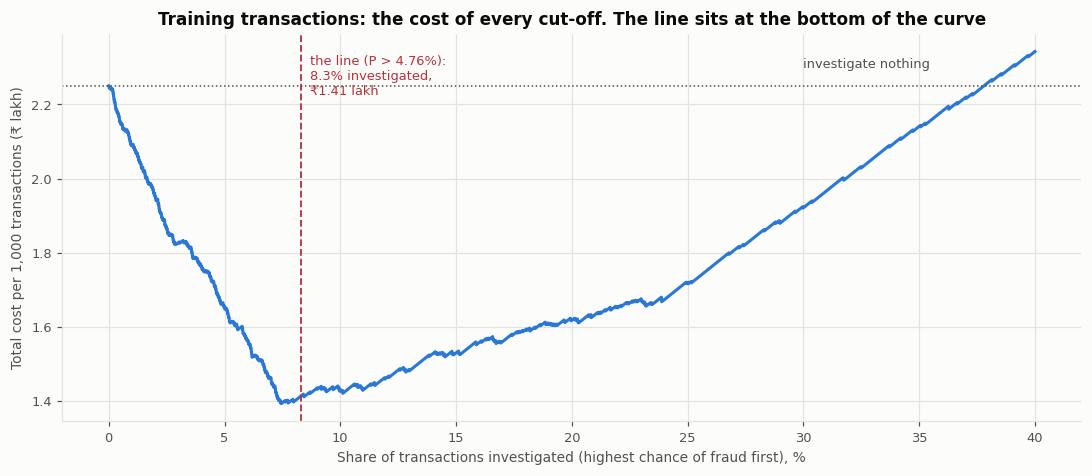

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.4))
c = curve_train[curve_train["Share investigated"] <= 0.40]
ax.plot(c["Share investigated"] * 100, c["Cost per 1,000 (₹)"] / LAKH, color=BLUE, lw=2)
ax.axvline(at_line["Share investigated"] * 100, color=FRAUD, ls="--", lw=1.2)
ax.text(at_line["Share investigated"] * 100 + 0.4, c["Cost per 1,000 (₹)"].max() / LAKH * 0.95,
        f"the line (P > 4.76%):\n{at_line['Share investigated']:.1%} investigated,\n₹{at_line['Cost per 1,000 (₹)'] / LAKH:.2f} lakh", fontsize=8.5, color=FRAUD)
ax.axhline(curve_train["Cost per 1,000 (₹)"].iloc[0] / LAKH, color=INK_2, ls=":", lw=1)
ax.text(30, curve_train["Cost per 1,000 (₹)"].iloc[0] / LAKH + 0.05, "investigate nothing", fontsize=8.5, color=INK_2)
ax.set_xlabel("Share of transactions investigated (highest chance of fraud first), %")
ax.set_ylabel("Total cost per 1,000 transactions (₹ lakh)")
ax.set_title("Training transactions: the cost of every cut-off. The line sits at the bottom of the curve")
fig.tight_layout(); save_chart(fig, "01_cost_curve_training"); plt.show()

## 5. The real cost on the 6,000 test transactions, used once

Each rule is set **before** looking at the test transactions, then applied to them:

| Rule | How it was set |
| --- | --- |
| **The line: investigate if P(fraud) > 4.76%** (the answer) | From the brief's costs |
| Sweep's cut-off | The cheapest cut-off on training transactions |
| Anomaly score (Task 3), its sweep's cut-off | The cheapest anomaly-score cut-off on training transactions |
| Investigate nothing / everything | For scale |

**95% ranges:** the test transactions are resampled 1,000 times; the saving against "investigate nothing" is recomputed each time.

In [7]:
def apply_rule(t: pd.DataFrame, investigate: np.ndarray) -> dict:
    """Cost and catch of one rule on a set of transactions (per 1,000 transactions)."""
    y, amt = t.Fraud_Flag.to_numpy(), t.Amount.to_numpy()
    per = 1000 / len(t)
    missed = ((~investigate) & (y == 1)).sum()
    wasted = (investigate & (y == 0)).sum()
    return {"Investigated per 1,000": investigate.sum() * per,
            "Frauds caught": (investigate & (y == 1)).sum() / y.sum(),
            "Fraud ₹ caught": (amt * y * investigate).sum() / (amt * y).sum(),
            "Frauds missed per 1,000": missed * per, "Honest checked per 1,000": wasted * per,
            "Cost per 1,000 (₹)": (MISSED_COST * missed + CHECK_COST * wasted) * per}


anom_curve = cost_curve(train, train.Anomaly_Score.to_numpy())
ANOM_CUT = float(anom_curve.loc[anom_curve["Cost per 1,000 (₹)"].idxmin(), "Cut-off"])
FINAL_CUT_RULE = "line" if CALIBRATION_OK else "sweep"
rules = {"The line: P(fraud) > 4.76%": test.P_fraud.to_numpy() > LINE,
         f"Sweep's cut-off: P(fraud) ≥ {SWEEP_CUT:.2%}": test.P_fraud.to_numpy() >= SWEEP_CUT,
         "Anomaly score, sweep's cut-off": test.Anomaly_Score.to_numpy() >= ANOM_CUT,
         "Investigate nothing": np.zeros(len(test), bool), "Investigate everything": np.ones(len(test), bool)}
results = pd.DataFrame({name: apply_rule(test, inv) for name, inv in rules.items()}).T

# 95% ranges for the saving against investigating nothing.
rng = np.random.default_rng(SEED)
y_t = test.Fraud_Flag.to_numpy()
savings = {name: [] for name in rules}
for _ in range(1000):
    i = rng.integers(0, len(test), len(test))
    none_cost = MISSED_COST * y_t[i].sum()
    for name, inv in rules.items():
        cost = MISSED_COST * ((~inv[i]) & (y_t[i] == 1)).sum() + CHECK_COST * (inv[i] & (y_t[i] == 0)).sum()
        savings[name].append((none_cost - cost) * 1000 / len(test))
results["Saving vs nothing per 1,000 (₹)"] = results["Cost per 1,000 (₹)"].iloc[3] - results["Cost per 1,000 (₹)"]
results["Saving 95% range"] = [f"₹{np.percentile(v, 2.5):,.0f} to ₹{np.percentile(v, 97.5):,.0f}" for v in savings.values()]
results["Saving %"] = results["Saving vs nothing per 1,000 (₹)"] / results["Cost per 1,000 (₹)"].iloc[3]
print(f"Calibration checks passed: {CALIBRATION_OK} → the answer uses the {FINAL_CUT_RULE}")
results.style.format({"Investigated per 1,000": "{:,.1f}", "Frauds caught": "{:.1%}", "Fraud ₹ caught": "{:.1%}",
                      "Frauds missed per 1,000": "{:,.2f}", "Honest checked per 1,000": "{:,.1f}",
                      "Cost per 1,000 (₹)": "₹{:,.0f}", "Saving vs nothing per 1,000 (₹)": "₹{:,.0f}", "Saving %": "{:.0%}"})

Calibration checks passed: True → the answer uses the line


,"Investigated per 1,000",Frauds caught,Fraud ₹ caught,"Frauds missed per 1,000","Honest checked per 1,000","Cost per 1,000 (₹)","Saving vs nothing per 1,000 (₹)",Saving 95% range,Saving %
The line: P(fraud) > 4.76%,79.0,52.1%,79.8%,11.50,66.5,"₹148,250","₹91,750","₹62,819 to ₹121,835",38%
Sweep's cut-off: P(fraud) ≥ 7.10%,75.5,51.4%,79.1%,11.67,63.2,"₹148,250","₹91,750","₹63,654 to ₹120,833",38%
"Anomaly score, sweep's cut-off",90.2,29.9%,55.9%,16.83,83.0,"₹209,833","₹30,167","₹9,496 to ₹52,585",13%
Investigate nothing,0.0,0.0%,0.0%,24.00,0.0,"₹240,000",₹0,₹0 to ₹0,0%
Investigate everything,"1,000.0",100.0%,100.0%,0.00,976.0,"₹488,000","₹-248,000","₹-291,750 to ₹-207,750",-103%


## 6. The finance view: counting each missed fraud at its real amount (decision M3-18)

The brief's flat ₹10,000 is the base. But the average fraud in this data is about ₹30,000, so the flat figure understates what missed frauds really cost. Here each missed fraud costs its **actual amount** (nothing recovered):

```text
Real cost = ₹ of the frauds let through + ₹500 × honest transactions investigated
Finance-view rule: investigate when P(fraud) × Amount > (1 − P(fraud)) × ₹500
```

Two questions on the test transactions:
1. What does the base rule (the 4.76% line) **really** save, in ₹?
2. How much more would the finance-view rule save?

In [8]:
def real_cost(t: pd.DataFrame, investigate: np.ndarray) -> dict:
    y, amt = t.Fraud_Flag.to_numpy(), t.Amount.to_numpy()
    per = 1000 / len(t)
    lost = (amt * y * (~investigate)).sum()
    wasted = (investigate & (y == 0)).sum()
    return {"Investigated per 1,000": investigate.sum() * per, "Frauds caught": (investigate & (y == 1)).sum() / y.sum(),
            "Fraud ₹ caught": (amt * y * investigate).sum() / (amt * y).sum(),
            "Fraud ₹ let through per 1,000": lost * per, "Checking cost per 1,000": CHECK_COST * wasted * per,
            "Real cost per 1,000 (₹)": (lost + CHECK_COST * wasted) * per}


p_t, amt_t = test.P_fraud.to_numpy(), test.Amount.to_numpy()
FIN_RULE = p_t * amt_t > (1 - p_t) * CHECK_COST
finance = pd.DataFrame({"Base rule: P(fraud) > 4.76%": real_cost(test, p_t > LINE),
                        "Finance-view rule: P × amount > (1 − P) × ₹500": real_cost(test, FIN_RULE),
                        "Investigate nothing": real_cost(test, np.zeros(len(test), bool)),
                        "Investigate everything": real_cost(test, np.ones(len(test), bool))}).T
finance["Real saving vs nothing per 1,000 (₹)"] = finance["Real cost per 1,000 (₹)"].iloc[2] - finance["Real cost per 1,000 (₹)"]
finance.style.format({"Investigated per 1,000": "{:,.1f}", "Frauds caught": "{:.1%}", "Fraud ₹ caught": "{:.1%}",
                      "Fraud ₹ let through per 1,000": "₹{:,.0f}", "Checking cost per 1,000": "₹{:,.0f}",
                      "Real cost per 1,000 (₹)": "₹{:,.0f}", "Real saving vs nothing per 1,000 (₹)": "₹{:,.0f}"})

,"Investigated per 1,000",Frauds caught,Fraud ₹ caught,"Fraud ₹ let through per 1,000","Checking cost per 1,000","Real cost per 1,000 (₹)","Real saving vs nothing per 1,000 (₹)"
Base rule: P(fraud) > 4.76%,79.0,52.1%,79.8%,"₹134,800","₹33,250","₹168,050","₹497,655"
Finance-view rule: P × amount > (1 − P) × ₹500,156.7,62.5%,89.3%,"₹71,360","₹70,833","₹142,194","₹523,512"
Investigate nothing,0.0,0.0%,0.0%,"₹665,705",₹0,"₹665,705",₹0
Investigate everything,"1,000.0",100.0%,100.0%,₹0,"₹488,000","₹488,000","₹177,705"


## 7. Board view in ₹, per 1,000 transactions

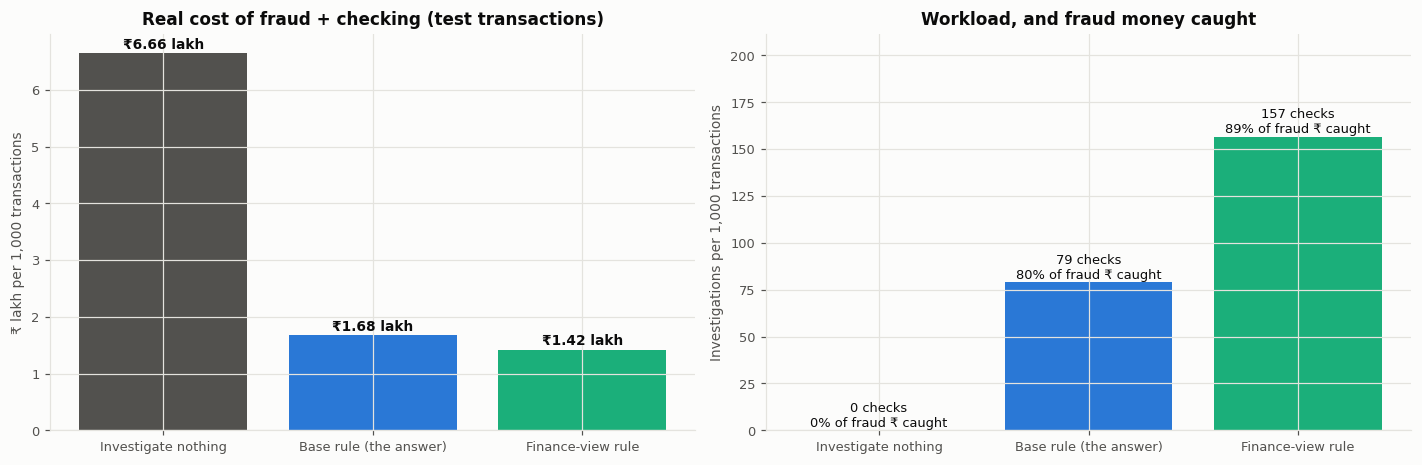

,"Investigations per 1,000","Cost, brief's costs (₹)","Cost, real amounts (₹)",Fraud ₹ caught
Investigate nothing,0,"₹240,000","₹665,705",0%
Base rule (the answer),79,"₹148,250","₹168,050",80%
Finance-view rule,157,—,"₹142,194",89%


In [9]:
board = pd.DataFrame({
    "Investigate nothing": [0, results.loc["Investigate nothing", "Cost per 1,000 (₹)"], finance.loc["Investigate nothing", "Real cost per 1,000 (₹)"], 0.0],
    "Base rule (the answer)": [results.iloc[0]["Investigated per 1,000"], results.iloc[0]["Cost per 1,000 (₹)"],
                               finance.iloc[0]["Real cost per 1,000 (₹)"], finance.iloc[0]["Fraud ₹ caught"]],
    "Finance-view rule": [finance.iloc[1]["Investigated per 1,000"], np.nan, finance.iloc[1]["Real cost per 1,000 (₹)"],
                          finance.iloc[1]["Fraud ₹ caught"]]},
    index=["Investigations per 1,000", "Cost, brief's costs (₹)", "Cost, real amounts (₹)", "Fraud ₹ caught"]).T

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
names = list(board.index)
cols = [INK_2, BLUE, AQUA]
axes[0].bar(names, board["Cost, real amounts (₹)"] / LAKH, color=cols)
for i, v in enumerate(board["Cost, real amounts (₹)"] / LAKH):
    axes[0].text(i, v + 0.08, f"₹{v:.2f} lakh", ha="center", fontsize=9, fontweight="bold")
axes[0].set_ylabel("₹ lakh per 1,000 transactions"); axes[0].set_title("Real cost of fraud + checking (test transactions)")
axes[1].bar(names, board["Investigations per 1,000"], color=cols)
for i, (v, c) in enumerate(zip(board["Investigations per 1,000"], board["Fraud ₹ caught"])):
    axes[1].text(i, v + 2, f"{v:.0f} checks\n{c:.0%} of fraud ₹ caught", ha="center", fontsize=8.5)
axes[1].set_ylabel("Investigations per 1,000 transactions"); axes[1].set_title("Workload, and fraud money caught")
axes[1].set_ylim(0, board["Investigations per 1,000"].max() * 1.35)
for ax in axes:
    ax.tick_params(axis="x", labelsize=8.5)
fig.tight_layout(); save_chart(fig, "02_board_view"); plt.show()
board.style.format({"Investigations per 1,000": "{:,.0f}", "Cost, brief's costs (₹)": "₹{:,.0f}",
                    "Cost, real amounts (₹)": "₹{:,.0f}", "Fraud ₹ caught": "{:.0%}"}, na_rep="—")

## 8. Risks and limitations: how the line moves if the costs change (decision M3-20)

The ₹10,000 and ₹500 are assumptions. The line depends only on their **ratio**: ₹20,000 / ₹500 gives the same line as ₹10,000 / ₹250. One compact table on the test transactions shows how the line, the workload and the cost move.

In [10]:
sens = []
for missed, check in [(10_000, 500), (5_000, 500), (20_000, 500), (10_000, 250), (10_000, 1_000)]:
    line = check / (missed + check)
    inv = test.P_fraud.to_numpy() > line
    y = test.Fraud_Flag.to_numpy()
    per = 1000 / len(test)
    cost = (missed * ((~inv) & (y == 1)).sum() + check * (inv & (y == 0)).sum()) * per
    sens.append({"Missed fraud (₹)": missed, "Wasted check (₹)": check, "Line": line,
                 "Investigated per 1,000": inv.sum() * per, "Frauds caught": (inv & (y == 1)).sum() / y.sum(),
                 "Cost per 1,000 (₹)": cost, "Investigate nothing (₹)": missed * y.sum() * per})
sens = pd.DataFrame(sens)
sens.style.format({"Missed fraud (₹)": "₹{:,.0f}", "Wasted check (₹)": "₹{:,.0f}", "Line": "{:.2%}",
                   "Investigated per 1,000": "{:,.0f}", "Frauds caught": "{:.0%}", "Cost per 1,000 (₹)": "₹{:,.0f}",
                   "Investigate nothing (₹)": "₹{:,.0f}"}).hide(axis="index")

Missed fraud (₹),Wasted check (₹),Line,"Investigated per 1,000",Frauds caught,"Cost per 1,000 (₹)",Investigate nothing (₹)
"₹10,000",₹500,4.76%,79,52%,"₹148,250","₹240,000"
"₹5,000",₹500,9.09%,74,51%,"₹90,083","₹120,000"
"₹20,000",₹500,2.44%,223,74%,"₹226,000","₹480,000"
"₹10,000",₹250,2.44%,223,74%,"₹113,000","₹240,000"
"₹10,000","₹1,000",9.09%,74,51%,"₹180,167","₹240,000"


## 9. What the results say

### The answer to the brief
**Investigate a transaction when the model's chance of fraud is above 4.76%.**

```text
4.76% = ₹500 ÷ (₹10,000 + ₹500): the point where a missed fraud's expected cost equals a wasted check's
```

- It comes straight from the brief's two costs, with no tuning.
- On the training transactions, the cheapest cut-off found by trying every one (7.10%) costs almost the same: ₹1.39 lakh vs ₹1.41 lakh per 1,000 transactions. The line sits at the bottom of the cost curve.

### Can the model's chances be trusted around the line? Yes (step 3)

| Set | Side of the line | Transactions | Predicted fraud rate | Actual fraud rate (95% range) | Pass |
| --- | --- | --- | --- | --- | --- |
| Training | Below | 22,009 | 1.17% | 1.15% (1.02–1.30%) | ✓ |
| Training | Above | 1,991 | 14.17% | 14.36% (12.89–15.97%) | ✓ |
| Test | Below | 5,526 | 1.19% | 1.25% (0.99–1.58%) | ✓ |
| Test | Above | 474 | 14.75% | 15.82% (12.81–19.38%) | ✓ |

All four checks pass, so the line is used as agreed.

### The real cost on the 6,000 test transactions, used once (step 5)

| Rule (set before seeing the test) | Investigated per 1,000 | Frauds caught | Fraud ₹ caught | Cost per 1,000 | Saving vs investigating nothing (95% range) |
| --- | --- | --- | --- | --- | --- |
| **The line: P(fraud) > 4.76%** | **79** | **52%** | **80%** | **₹1.48 lakh** | **₹91,750 = 38% (₹62,819 to ₹1,21,835)** |
| Sweep's cut-off (P ≥ 7.10%) | 76 | 51% | 79% | ₹1.48 lakh | ₹91,750 = 38% |
| Anomaly score (Task 3), sweep's cut-off | 90 | 30% | 56% | ₹2.10 lakh | ₹30,167 = 13% |
| Investigate nothing | 0 | 0% | 0% | ₹2.40 lakh | — |
| Investigate everything | 1,000 | 100% | 100% | ₹4.88 lakh | −₹2.48 lakh (−103%) |

- **The line cuts the cost by 38%** against investigating nothing, and the saving is beyond chance.
- **It investigates 79 of every 1,000 transactions** (8%), and catches half the frauds and 80% of the fraud money.
- **The line and the sweep give the same cost on new data.** Tuning a cut-off on past data buys nothing.
- **A threshold on the anomaly score saves only 13%.** Task 3's conclusion holds in cost terms too.
- **Investigating everything costs twice as much as investigating nothing.** Checking all 976 honest transactions per 1,000 costs more than the frauds it would stop.

### The finance view: what it really saves, in ₹ (step 6)

Counting each missed fraud at its real amount (average about ₹30,000, nothing recovered):

| Rule | Investigated per 1,000 | Fraud ₹ caught | Fraud ₹ let through | Checking cost | **Real cost per 1,000** | Real saving |
| --- | --- | --- | --- | --- | --- | --- |
| Investigate nothing | 0 | 0% | ₹6.66 lakh | ₹0 | **₹6.66 lakh** | — |
| **Base rule (the answer)** | 79 | 80% | ₹1.35 lakh | ₹0.33 lakh | **₹1.68 lakh** | **₹4.98 lakh (75%)** |
| Finance-view rule (P × amount > (1 − P) × ₹500) | 157 | 89% | ₹0.71 lakh | ₹0.71 lakh | **₹1.42 lakh** | ₹5.24 lakh (79%) |
| Investigate everything | 1,000 | 100% | ₹0 | ₹4.88 lakh | ₹4.88 lakh | ₹1.78 lakh |

- **The brief's flat ₹10,000 understates what fraud really costs.** The true cost of investigating nothing is ₹6.66 lakh per 1,000 transactions, not the ₹2.40 lakh the brief's costs suggest. So the base rule's real saving is **₹4.98 lakh per 1,000 transactions (75%)**, not ₹0.92 lakh.
- **The finance-view rule saves a further ₹26,000 per 1,000 transactions,** but needs twice the investigations: 157 against 79. Whether that is worth it depends on whether the bank can staff it. Each extra check costs ₹500, and the extra 78 checks recover about ₹63,000 more in fraud.

### Risks and limitations: how the line moves if the costs change (step 8)

| Missed fraud | Wasted check | Line | Investigated per 1,000 | Frauds caught | Cost per 1,000 | Investigate nothing |
| --- | --- | --- | --- | --- | --- | --- |
| **₹10,000** | **₹500** | **4.76%** | **79** | **52%** | **₹1.48 lakh** | ₹2.40 lakh |
| ₹5,000 | ₹500 | 9.09% | 74 | 51% | ₹0.90 lakh | ₹1.20 lakh |
| ₹20,000 | ₹500 | 2.44% | 223 | 74% | ₹2.26 lakh | ₹4.80 lakh |
| ₹10,000 | ₹250 | 2.44% | 223 | 74% | ₹1.13 lakh | ₹2.40 lakh |
| ₹10,000 | ₹1,000 | 9.09% | 74 | 51% | ₹1.80 lakh | ₹2.40 lakh |

- **Only the ratio of the two costs matters.** ₹20,000 / ₹500 gives the same line as ₹10,000 / ₹250.
- **The workload jumps.** If missing a fraud is 40 times as costly as a check (instead of 20), the line drops to 2.44%, and investigations nearly triple, from 79 to 223 per 1,000. The model gives many transactions chances of 2–5%. Before staffing an investigation team, the Board should settle these two costs.
- **The model's chances are calibrated only as far as checked:** on each side of the line, on these 20 months of data. They should be re-checked as fraud patterns change.

### Output
- `outputs/task4/FINAL_M3_T4_transaction_decisions.csv`: every transaction's chance of fraud, the expected cost each way (for example, let through ₹200 vs investigate ₹490), the decision under the brief's costs and under the finance view, and whether it was fraud.
- `outputs/task4/threshold_summary.csv`: each rule's cost on the test transactions.

## 10. Save the outputs (decision M3-20)

- **`FINAL_M3_T4_transaction_decisions.csv`: the brief's threshold applied to every transaction.** P(fraud), the expected cost of letting it through and of investigating it, the decision under the base rule and the finance view, and whether it was fraud.
- **`threshold_summary.csv`:** each rule's cost on the test transactions, against investigating nothing and everything.
- The charts above and `key_numbers.json`.

In [11]:
decisions = pd.DataFrame({
    "Transaction_ID": df.Transaction_ID, "Set": df.Set, "Amount (₹)": df.Amount.round(2), "P(fraud)": df.P_fraud.round(6),
    "Expected cost if let through (₹)": (df.P_fraud * MISSED_COST).round(2),
    "Expected cost if investigated (₹)": ((1 - df.P_fraud) * CHECK_COST).round(2),
    "Decision (brief's costs)": np.where(df.P_fraud > LINE, "Investigate", "Let through"),
    "Expected ₹ lost if let through (P × amount)": (df.P_fraud * df.Amount).round(2),
    "Decision (finance view)": np.where(df.P_fraud * df.Amount > (1 - df.P_fraud) * CHECK_COST, "Investigate", "Let through"),
    "Actually fraud": np.where(df.Fraud_Flag == 1, "Yes", "No")})
assert decisions.notna().all().all() and len(decisions) == 30000
save_table(decisions, "FINAL_M3_T4_transaction_decisions")

summary = pd.concat([results.reset_index(names="Rule").assign(View="Brief's costs (₹10,000 / ₹500)"),
                     finance.reset_index(names="Rule").assign(View="Real amounts (finance view)")], ignore_index=True)
save_table(summary.round(4), "threshold_summary")


def r4(v):
    return round(float(v), 4)


key = {"line": r4(LINE), "calibration_ok": CALIBRATION_OK, "sweep_cut": r4(SWEEP_CUT), "anomaly_cut": r4(ANOM_CUT),
       "test": {n: {k: r4(v) for k, v in row.items() if isinstance(v, (int, float, np.floating))} for n, row in results.iterrows()},
       "finance": {n: {k: r4(v) for k, v in row.items()} for n, row in finance.iterrows()},
       "decisions_investigate": {s: int(v) for s, v in decisions[decisions["Decision (brief's costs)"] == "Investigate"].groupby("Set").size().items()}}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1, ensure_ascii=False), encoding="utf-8")
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(sorted(p.name for p in OUT_DIR.iterdir()))

Saved to module_03_fraud_detection/outputs/task4
['01_cost_curve_training.png', '02_board_view.png', 'FINAL_M3_T4_transaction_decisions.csv', 'key_numbers.json', 'threshold_summary.csv']


## What goes to Module 9: Digital banking's fraud cost in the standard fields (decision M3-21)
Module 9 compares every business on the same fields. This module gives Digital banking its **cost side**: the cost of fraud risk per ₹ of money moved, with and without the ML rule, and a bad year (fraud three times as common, the stress named in the project plan). **Digital banking's revenue is not in the data** (no fees in the transaction file); its return per ₹ of capital comes from Module 1's Digital Banking and Payments units.

In [12]:
M9_COLS = ["Category", "What NovaFin would put money into", "Return per ₹ deployed (% a year)", "Return range (% a year)",
           "Bad-year result per ₹ (% a year)", "How the bad year is defined", "Capacity (₹ crore)", "Evidence strength",
           "How fast the money can come back", "Data gap or assumption", "Controls", "Detail tab", "Detail column(s)", "Decision"]
D4 = pd.read_csv(OUT_DIR / "FINAL_M3_T4_transaction_decisions.csv"); t4 = D4[D4.Set == "test"]
AMT, DEC, FRAUD = "Amount (₹)", "Decision (brief's costs)", "Actually fraud"
moved = t4[AMT].sum(); lost_none = t4.loc[t4[FRAUD] == "Yes", AMT].sum()
lost_rule = t4.loc[(t4[FRAUD] == "Yes") & (t4[DEC] == "Let through"), AMT].sum()
check_cost = 500 * int(((t4[DEC] == "Investigate") & (t4[FRAUD] == "No")).sum())          # brief's ₹500 per honest transaction checked
cost_rule, cost_none = 100 * (lost_rule + check_cost) / moved, 100 * lost_none / moved
bad_rule, bad_none = 100 * (3 * lost_rule + check_cost) / moved, 3 * cost_none
m9_inputs = pd.DataFrame([{"Category": "Digital banking: cost of fraud risk", "What NovaFin would put money into": "The ML fraud rule (P(fraud) > 4.76%) on Digital banking's payments",
    "Return per ₹ deployed (% a year)": round(-cost_rule, 2), "Return range (% a year)": f"−{cost_rule:.2f}% with the rule vs −{cost_none:.2f}% with no screening (per ₹ of money moved)",
    "Bad-year result per ₹ (% a year)": round(-bad_rule, 2), "How the bad year is defined": f"Fraud three times as common (missed fraud × 3); no screening: −{bad_none:.2f}%",
    "Capacity (₹ crore)": "Scales with the money moved", "Evidence strength": "Strong: tested on unseen transactions; costs from the brief",
    "How fast the money can come back": "Not a capital use: a cost per ₹ moved", "Data gap or assumption": "No fee revenue in the data: Digital banking's return per ₹ of capital comes from Module 1 (Digital Banking 13.2%, Payments 13.0%)",
    "Controls": "Investigate above 4.76%; review the line monthly; staff 79 investigations per 1,000 transactions", "Detail tab": "T4 transaction decisions",
    "Detail column(s)": f"{AMT}, {DEC}, {FRAUD}", "Decision": "M3-21"}])[M9_COLS]
m9_inputs.to_csv(OUT_DIR / "module9_inputs.csv", index=False)
print(f"Cost of fraud risk per ₹ moved: {cost_rule:.2f}% with the rule (no screening {cost_none:.2f}%); fraud × 3: {bad_rule:.2f}% (no screening {bad_none:.2f}%)")
display(m9_inputs.T)

Cost of fraud risk per ₹ moved: 1.55% with the rule (no screening 6.13%); fraud × 3: 4.03% (no screening 18.38%)


,0
Category,Digital banking: cost of fraud risk
What NovaFin would put money into,The ML fraud rule (P(fraud) > 4.76%) on Digita...
Return per ₹ deployed (% a year),-1.55
Return range (% a year),−1.55% with the rule vs −6.13% with no screeni...
Bad-year result per ₹ (% a year),-4.03
How the bad year is defined,Fraud three times as common (missed fraud × 3)...
Capacity (₹ crore),Scales with the money moved
Evidence strength,Strong: tested on unseen transactions; costs f...
How fast the money can come back,Not a capital use: a cost per ₹ moved
Data gap or assumption,No fee revenue in the data: Digital banking's ...
